# Lab 5: Hierarchical and DBSCAN Clustering

**Name:** Todd Simonson
**Course:** MSCS-634: Advanced Big Data and Data Mining
**Instructor:** Dr. Satish Penmatsa
**Assignment:** Lab 5: Clustering the Wine Dataset with Agglomerative Hierarchical Clustering and DBSCAN

## Step 1: Data Preparation and Exploration

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, homogeneity_score, completeness_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
RANDOM_STATE = 42

In [2]:
wine = load_wine(as_frame=True)
X_raw = wine.data
y = wine.target.values
class_names = [str(n) for n in wine.target_names]
X_raw.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
X_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
dtypes: float64(13)
m

In [4]:
X_raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


In [5]:
counts = pd.Series(y).value_counts().sort_index()
counts.index = class_names
print(counts.to_string())

class_0    59
class_1    71
class_2    48


**Observation:** The dataset has 178 wines from three cultivars (59 class_0, 71 class_1, 48 class_2) and 13 numeric chemical measurements, all complete with no missing values. The features are on very different scales: proline averages 746.9 with a standard deviation of 314.9, magnesium averages 99.7 (standard deviation 14.3), and hue averages 0.96 (standard deviation 0.23). The two-dimensional PCA view, which captures 55.4% of the variance, shows the three cultivars as an arc: class_2 on the left, class_1 along the bottom, and class_0 on the right. Class_2 and class_0 are compact. Class_1 is spread out and touches both of the other groups, so any clustering method is likely to struggle at its edges.

### Standardization

Both algorithms group wines by distance, so features are standardized to a mean of 0 and a standard deviation of 1. Without this step, proline (range 278 to 1,680) would dominate every distance calculation, as shown in Lab 2.

In [6]:
X = StandardScaler().fit_transform(X_raw)
print('means after scaling:', X.mean(axis=0).round(3)[:5], '...')
print('standard deviations after scaling:', X.std(axis=0).round(3)[:5], '...')

means after scaling: [ 0.  0. -0. -0. -0.] ...
standard deviations after scaling: [1. 1. 1. 1. 1.] ...


### A two-dimensional view for plotting

Clustering is done in all 13 standardized dimensions. For scatter plots only, the data is projected onto its first two principal components.

variance explained by PC1 and PC2: [0.362 0.192] (total 55.4%)


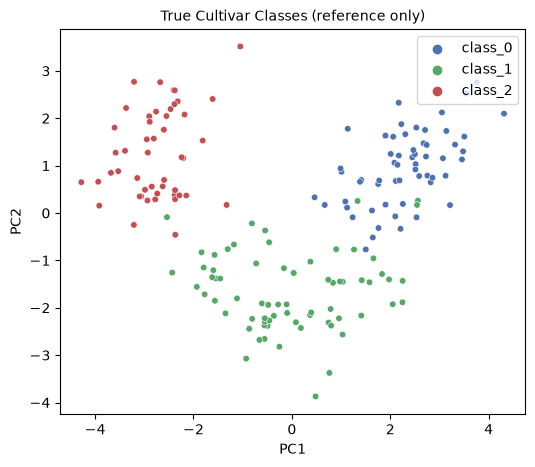

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
print('variance explained by PC1 and PC2:', pca.explained_variance_ratio_.round(3),
      f'(total {pca.explained_variance_ratio_.sum():.1%})')

palette = np.array(['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#DD8452', '#937860', '#DA8BC3', '#8C8C8C', '#CCB974', '#64B5CD'])

def scatter(ax, labels, title):
    # clusters in color, dbscan noise (label -1) as gray x markers
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X_2d[~noise, 0], X_2d[~noise, 1], c=palette[labels[~noise] % len(palette)], s=22,
               edgecolor='white', linewidth=0.4)
    if noise.any():
        ax.scatter(X_2d[noise, 0], X_2d[noise, 1], c='gray', marker='x', s=22, linewidth=1,
                   label=f'Noise ({noise.sum()})')
        ax.legend(loc='upper right', fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

fig, ax = plt.subplots(figsize=(6, 5))
scatter(ax, y, 'True Cultivar Classes (reference only)')
for i, n in enumerate(class_names):
    ax.scatter([], [], c=palette[i], label=n)
ax.legend(loc='upper right')
plt.show()

### Evaluation metrics

* **Silhouette score** (−1 to 1) measures how well separated the clusters are, using only the data. Higher is better.
* **Homogeneity** (0 to 1) is 1 when every cluster contains wines from only one cultivar.
* **Completeness** (0 to 1) is 1 when all wines from a cultivar end up in the same cluster.
* **Adjusted Rand Index** (ARI) is added as a single summary of agreement with the true classes (0 means random, 1 means perfect).

The true labels are used only to score the results, never to form the clusters.

In [8]:
def metrics(labels, X_data=X, drop_noise_for_silhouette=True):
    labels = np.asarray(labels)
    mask = labels != -1 if drop_noise_for_silhouette else np.ones(len(labels), bool)
    n_clusters = len(set(labels[labels != -1]))
    sil = silhouette_score(X_data[mask], labels[mask]) if n_clusters >= 2 else np.nan
    return {'clusters': n_clusters, 'noise points': int((labels == -1).sum()),
            'silhouette': sil, 'homogeneity': homogeneity_score(y, labels),
            'completeness': completeness_score(y, labels), 'ARI': adjusted_rand_score(y, labels)}

## Step 2: Agglomerative Hierarchical Clustering

Agglomerative clustering starts with every wine as its own cluster and repeatedly merges the two closest clusters until the requested number remains. The default **Ward linkage** merges the pair that increases total within-cluster variance the least.

### Testing different values of n_clusters

In [9]:
hier_rows, hier_labels = [], {}
for k in [2, 3, 4, 5, 6]:
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X)
    hier_labels[k] = labels
    hier_rows.append({'n_clusters': k, **metrics(labels), 'cluster sizes': np.bincount(labels).tolist()})
hier_df = pd.DataFrame(hier_rows).drop(columns=['clusters', 'noise points']).set_index('n_clusters')
hier_df.round(4)

,silhouette,homogeneity,completeness,ARI,cluster sizes
n_clusters,,,,,
2,0.2670,0.4441,0.7745,0.4394,"[122, 56]"
3,0.2774,0.7904,0.7825,0.7899,"[58, 56, 64]"
4,0.2258,0.7904,0.6490,0.6568,"[56, 30, 64, 28]"
5,0.1867,0.8106,0.5762,0.5830,"[64, 30, 36, 28, 20]"
6,0.1797,0.8348,0.5530,0.5757,"[30, 58, 36, 28, 20, 6]"


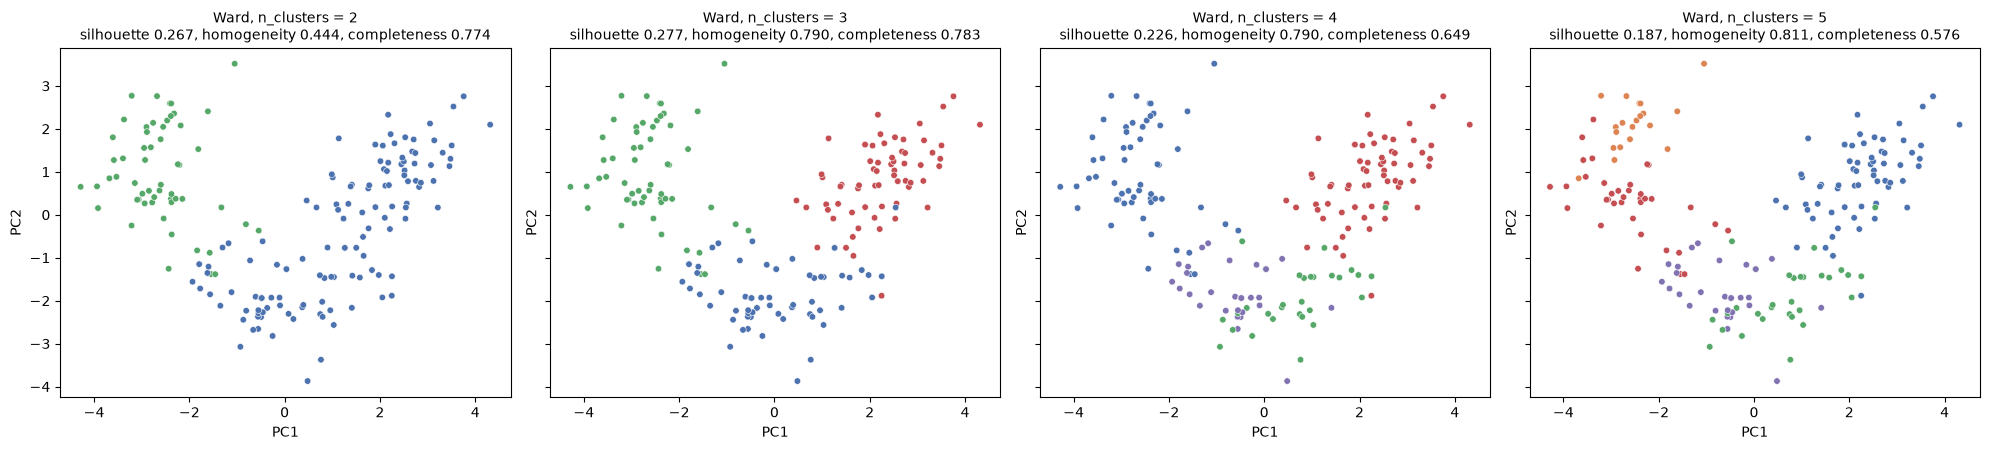

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharex=True, sharey=True)
for ax, k in zip(axes, [2, 3, 4, 5]):
    r = hier_df.loc[k]
    scatter(ax, hier_labels[k], f'Ward, n_clusters = {k}\nsilhouette {r.silhouette:.3f}, homogeneity {r.homogeneity:.3f}, completeness {r.completeness:.3f}')
plt.tight_layout()
plt.show()

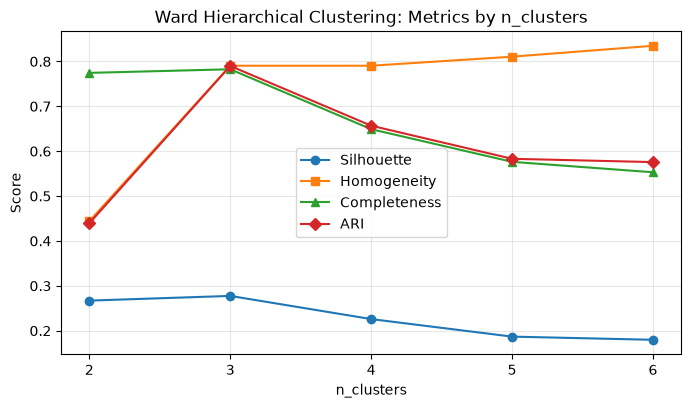

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for col, m in [('silhouette', 'o'), ('homogeneity', 's'), ('completeness', '^'), ('ARI', 'D')]:
    ax.plot(hier_df.index, hier_df[col], marker=m, label=col.capitalize() if col != 'ARI' else 'ARI')
ax.set_xticks(hier_df.index)
ax.set_xlabel('n_clusters')
ax.set_ylabel('Score')
ax.set_title('Ward Hierarchical Clustering: Metrics by n_clusters')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Observation:** Three clusters is the best choice on every overall measure: the highest silhouette (0.2774) and the best balance of homogeneity (0.7904) and completeness (0.7825), giving the highest ARI (0.7899). With 2 clusters, class_0 and most of class_1 are merged into one 122-wine group, so completeness stays high (0.7745) but homogeneity drops to 0.4441. Above 3 clusters, homogeneity keeps rising (to 0.8348 at 6) because smaller clusters are purer, but completeness falls (to 0.5530) because each cultivar is split across several clusters. Silhouette also declines steadily, from 0.2774 to 0.1797. This trade-off is what the two label-based metrics are designed to show: one rewards pure clusters, the other rewards keeping each class together, and only the correct number of groups does well on both.

### Comparing linkage methods (n_clusters = 3)

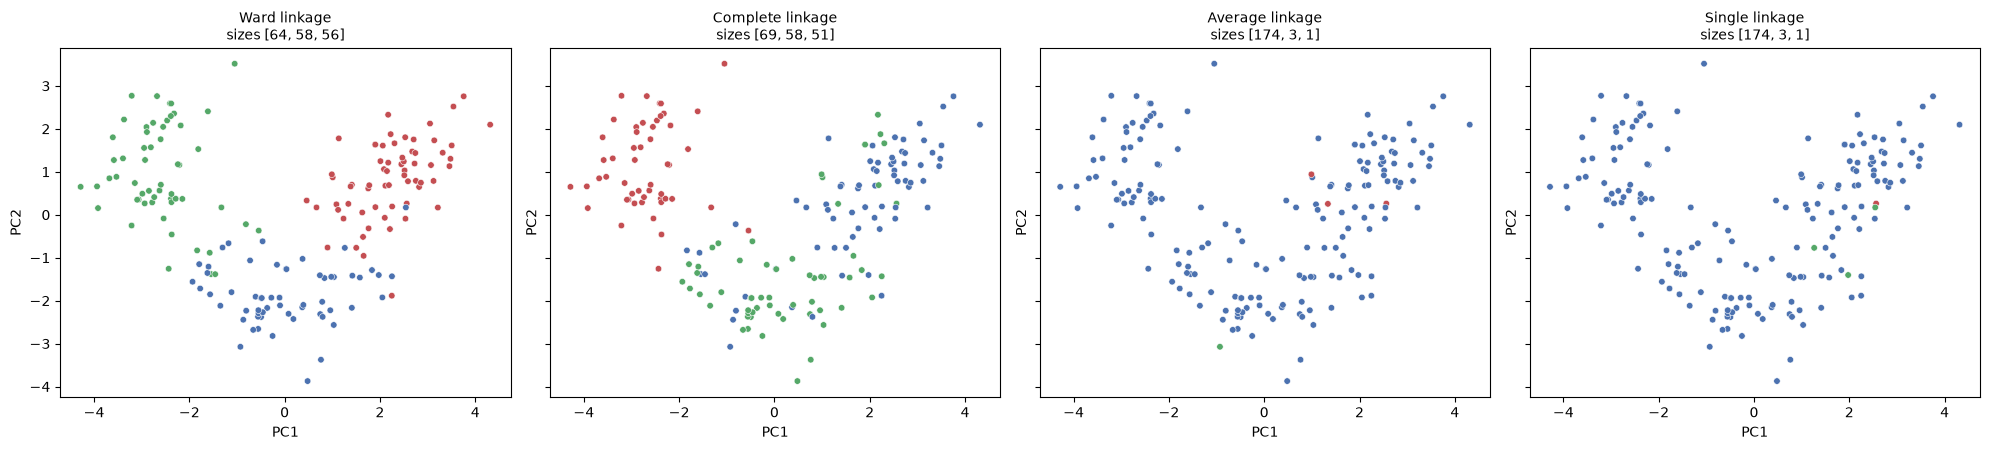

,silhouette,homogeneity,completeness,ARI,cluster sizes
linkage,,,,,
ward,0.2774,0.7904,0.7825,0.7899,"[64, 58, 56]"
complete,0.2038,0.6157,0.6130,0.5771,"[69, 58, 51]"
average,0.1575,0.0102,0.0926,-0.0054,"[174, 3, 1]"
single,0.1827,0.0194,0.1752,-0.0068,"[174, 3, 1]"


In [12]:
link_rows, link_labels = [], {}
for link in ['ward', 'complete', 'average', 'single']:
    labels = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(X)
    link_labels[link] = labels
    link_rows.append({'linkage': link, **metrics(labels), 'cluster sizes': sorted(np.bincount(labels).tolist(), reverse=True)})
link_df = pd.DataFrame(link_rows).drop(columns=['clusters', 'noise points']).set_index('linkage')

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6), sharex=True, sharey=True)
for ax, link in zip(axes, link_df.index):
    scatter(ax, link_labels[link], f"{link.capitalize()} linkage\nsizes {link_df.loc[link, 'cluster sizes']}")
plt.tight_layout()
plt.show()
link_df.round(4)

**Observation:** The linkage method matters more than the number of clusters. Ward linkage gives three balanced clusters (64, 58, 56) that closely match the cultivars. Complete linkage is weaker but still meaningful (ARI 0.5771). Average and single linkage fail completely: each produces one 174-wine cluster plus two tiny clusters of 3 and 1 wines, with an ARI near zero. Single linkage merges clusters based on their two closest points, so it chains through the overlapping class_1 region and joins everything into one group, while a few isolated wines end up as their own clusters. Average linkage behaves the same way here. Ward linkage avoids this because it penalizes merges that make a cluster spread out.

### Dendrogram

last five merge heights: [11.72 12.23 12.57 27.65 35.4 ]
cut height for 3 clusters: 20.11


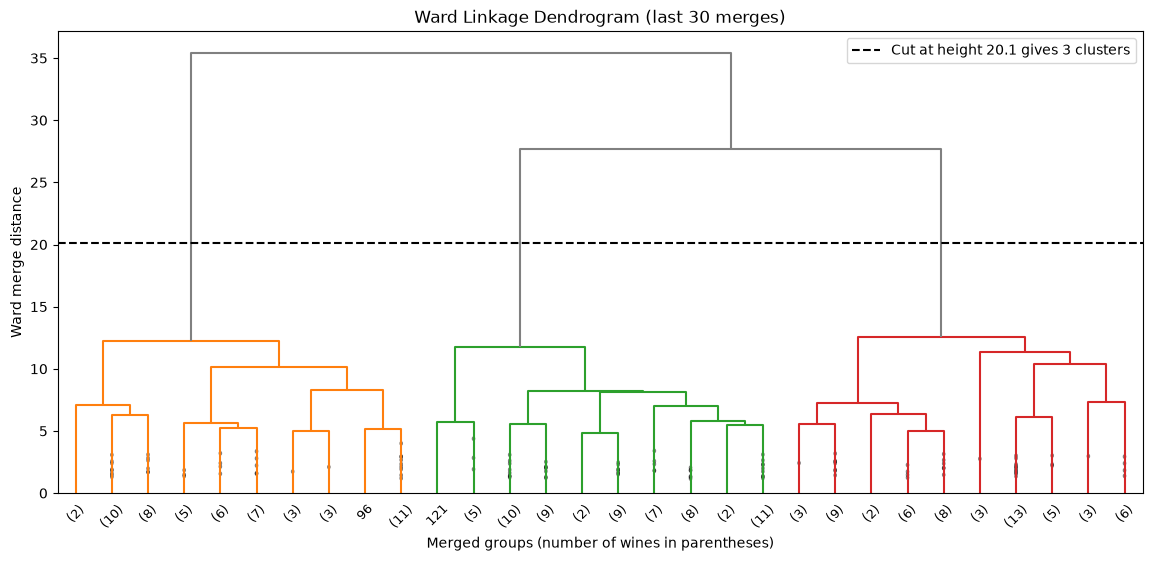

In [13]:
Z = linkage(X, method='ward')

# height that cuts the tree into exactly 3 clusters: between the 3rd- and 2nd-to-last merges
heights = Z[:, 2]
cut = (heights[-3] + heights[-2]) / 2
print('last five merge heights:', heights[-5:].round(2))
print(f'cut height for 3 clusters: {cut:.2f}')

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=cut, show_contracted=True,
           leaf_font_size=9, ax=ax, above_threshold_color='gray')
ax.axhline(cut, color='black', linestyle='--', label=f'Cut at height {cut:.1f} gives 3 clusters')
ax.set_xlabel('Merged groups (number of wines in parentheses)')
ax.set_ylabel('Ward merge distance')
ax.set_title('Ward Linkage Dendrogram (last 30 merges)')
ax.legend()
plt.show()

In [14]:
# compare the 3-cluster ward solution with the true classes
pd.crosstab(pd.Series([class_names[i] for i in y], name='true class'),
            pd.Series(hier_labels[3], name='ward cluster'))

ward cluster,0,1,2
true class,,,
class_0,0,0,59
class_1,58,8,5
class_2,0,48,0


**Observation:** The dendrogram shows three clear groups. Within-group merges all happen below a height of about 12.6, but the final two merges jump to 27.65 and 35.40. A large gap like this between merge heights is the standard sign of where to cut the tree. Any cut between 12.6 and 27.6 (for example, the dashed line at 20.1) yields the same three clusters, so the 3-cluster result is not sensitive to the exact cut height. The order of the last merges is also informative. The class_0 and class_1 groups join first (at 27.65), and the class_2 group (the 56 wines on the left) joins last (at 35.40), so class_2 is the most chemically distinct cultivar. The crosstab confirms the result: every class_0 and class_2 wine is assigned correctly, and the only 13 mismatches are class_1 wines grouped with class_2 (8) or class_0 (5).

## Step 3: DBSCAN Clustering

DBSCAN (Density-Based Spatial Clustering of Applications with Noise) grows clusters out of dense regions instead of requiring a number of clusters up front.

* **eps:** the radius that defines a point's neighborhood.
* **min_samples:** the number of points, including the point itself, that must fall within eps for a point to be a *core point*.

Clusters are chains of core points within eps of each other. Non-core points near a cluster are *border points*. Everything else is labeled **noise** (label −1).

### Choosing a starting eps: the k-distance plot

A common heuristic sorts every point's distance to its k-th nearest neighbor (k = min_samples) and picks eps at the "elbow," where the curve bends upward.

elbow at sorted position 144 of 178: eps = 2.71


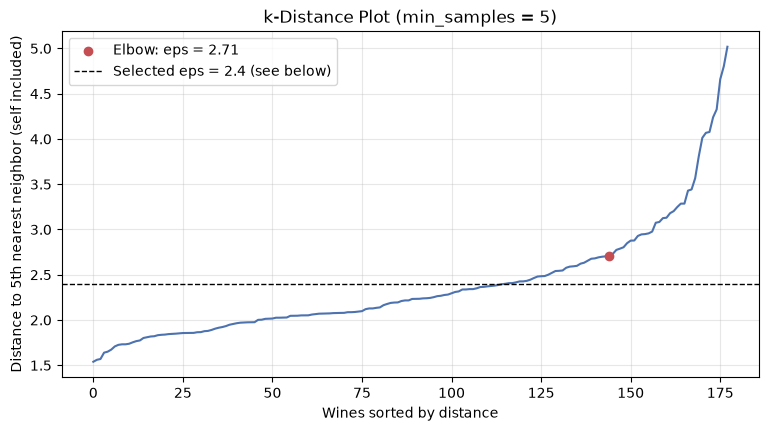

In [15]:
k = 5
kdist = np.sort(NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1])

# elbow = the point farthest from the straight line joining the curve's endpoints
x = np.arange(len(kdist))
v = np.array([len(kdist) - 1, kdist[-1] - kdist[0]])
v = v / np.linalg.norm(v)
pts = np.c_[x, kdist - kdist[0]]
elbow = np.linalg.norm(pts - np.outer(pts @ v, v), axis=1).argmax()
print(f'elbow at sorted position {elbow} of {len(kdist)}: eps = {kdist[elbow]:.2f}')

plt.figure(figsize=(9, 4.5))
plt.plot(kdist, color='#4C72B0')
plt.scatter(elbow, kdist[elbow], color='#C44E52', zorder=3, label=f'Elbow: eps = {kdist[elbow]:.2f}')
plt.axhline(2.4, color='black', linestyle='--', linewidth=1, label='Selected eps = 2.4 (see below)')
plt.xlabel('Wines sorted by distance')
plt.ylabel(f'Distance to {k}th nearest neighbor (self included)')
plt.title('k-Distance Plot (min_samples = 5)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Experimenting with eps and min_samples

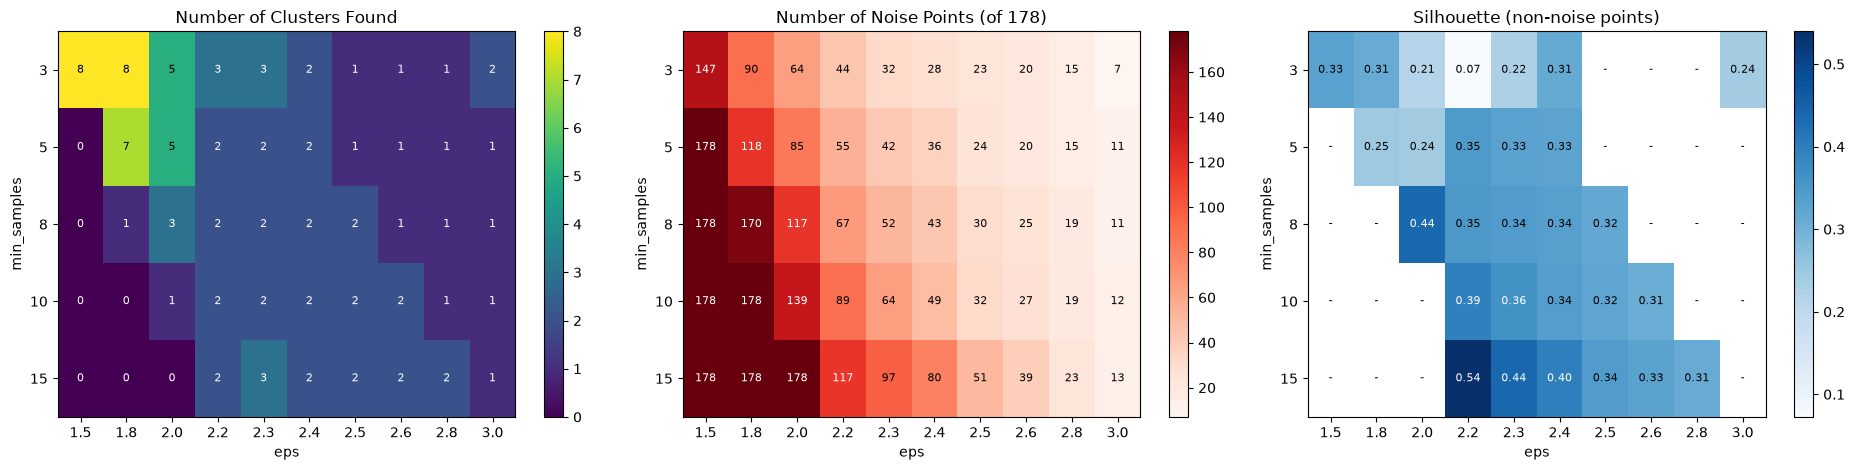

In [16]:
eps_values = [1.5, 1.8, 2.0, 2.2, 2.3, 2.4, 2.5, 2.6, 2.8, 3.0]
ms_values = [3, 5, 8, 10, 15]
grid = []
for eps in eps_values:
    for ms in ms_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
        grid.append({'eps': eps, 'min_samples': ms, **metrics(labels)})
grid_df = pd.DataFrame(grid)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, col, cmap, fmt in [(axes[0], 'clusters', 'viridis', 'd'), (axes[1], 'noise points', 'Reds', 'd'),
                           (axes[2], 'silhouette', 'Blues', '.2f')]:
    pivot = grid_df.pivot(index='min_samples', columns='eps', values=col)
    im = ax.imshow(pivot.values, cmap=cmap, aspect='auto')
    ax.set_xticks(range(len(eps_values))); ax.set_xticklabels(eps_values)
    ax.set_yticks(range(len(ms_values))); ax.set_yticklabels(ms_values)
    vmin, vmax = np.nanmin(pivot.values), np.nanmax(pivot.values)
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            # white text on dark cells so every value stays readable
            dark = (not pd.isna(val)) and ((val - vmin) / (vmax - vmin + 1e-9) > 0.6 if col != 'clusters' else (val - vmin) / (vmax - vmin + 1e-9) < 0.45)
            ax.text(j, i, '-' if pd.isna(val) else format(int(val) if fmt == 'd' else val, fmt),
                    ha='center', va='center', fontsize=8, color='white' if dark else 'black')
    ax.set_xlabel('eps'); ax.set_ylabel('min_samples')
    ax.set_title({'clusters': 'Number of Clusters Found', 'noise points': 'Number of Noise Points (of 178)',
                  'silhouette': 'Silhouette (non-noise points)'}[col])
    plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

In [17]:
grid_df.round(3).set_index(['eps', 'min_samples']).loc[[(1.8, 5), (2.0, 5), (2.2, 5), (2.4, 5), (2.6, 5), (2.8, 5), (2.4, 10), (2.4, 15)]]

clusters  noise points  silhouette  homogeneity  completeness    ARI
eps min_samples                                                                      
1.8 5                   7           118       0.246        0.354         0.307  0.084
2.0 5                   5            85       0.240        0.362         0.325  0.220
2.2 5                   2            55       0.348        0.410         0.428  0.329
2.4 5                   2            36       0.327        0.504         0.552  0.421
2.6 5                   1            20         NaN        0.052         0.161 -0.000
2.8 5                   1            15         NaN        0.048         0.182 -0.004
2.4 10                  2            49       0.338        0.411         0.444  0.328
    15                  2            80       0.397        0.395         0.435  0.325

**Observation:** DBSCAN is very sensitive to its parameters on this dataset:

* **eps too small (1.5 to 2.0):** most wines are noise, and the rest break into many small clusters. At eps = 1.8 and min_samples = 5, there are 7 clusters and 118 of the 178 wines are noise.
* **eps in a narrow middle range (2.2 to 2.4 at min_samples = 5):** two stable clusters appear, with 36 to 55 noise points.
* **eps too large (2.6 and up at min_samples = 5):** the clusters merge into one group of 158 or more wines, which carries almost no information about the cultivars (ARI near 0).
* **Increasing min_samples** at a fixed eps raises the bar for core points. At eps = 2.4, the noise count rises from 36 (min_samples = 5) to 49 (10) to 80 (15). It also shifts the merge point upward: with min_samples = 15, two clusters persist until eps = 2.8.

DBSCAN never finds the three cultivars as three substantial clusters. The few settings that report 3 clusters do so with one tiny cluster (3 wines) or with more than half the wines labeled noise.

### Visualizing parameter effects

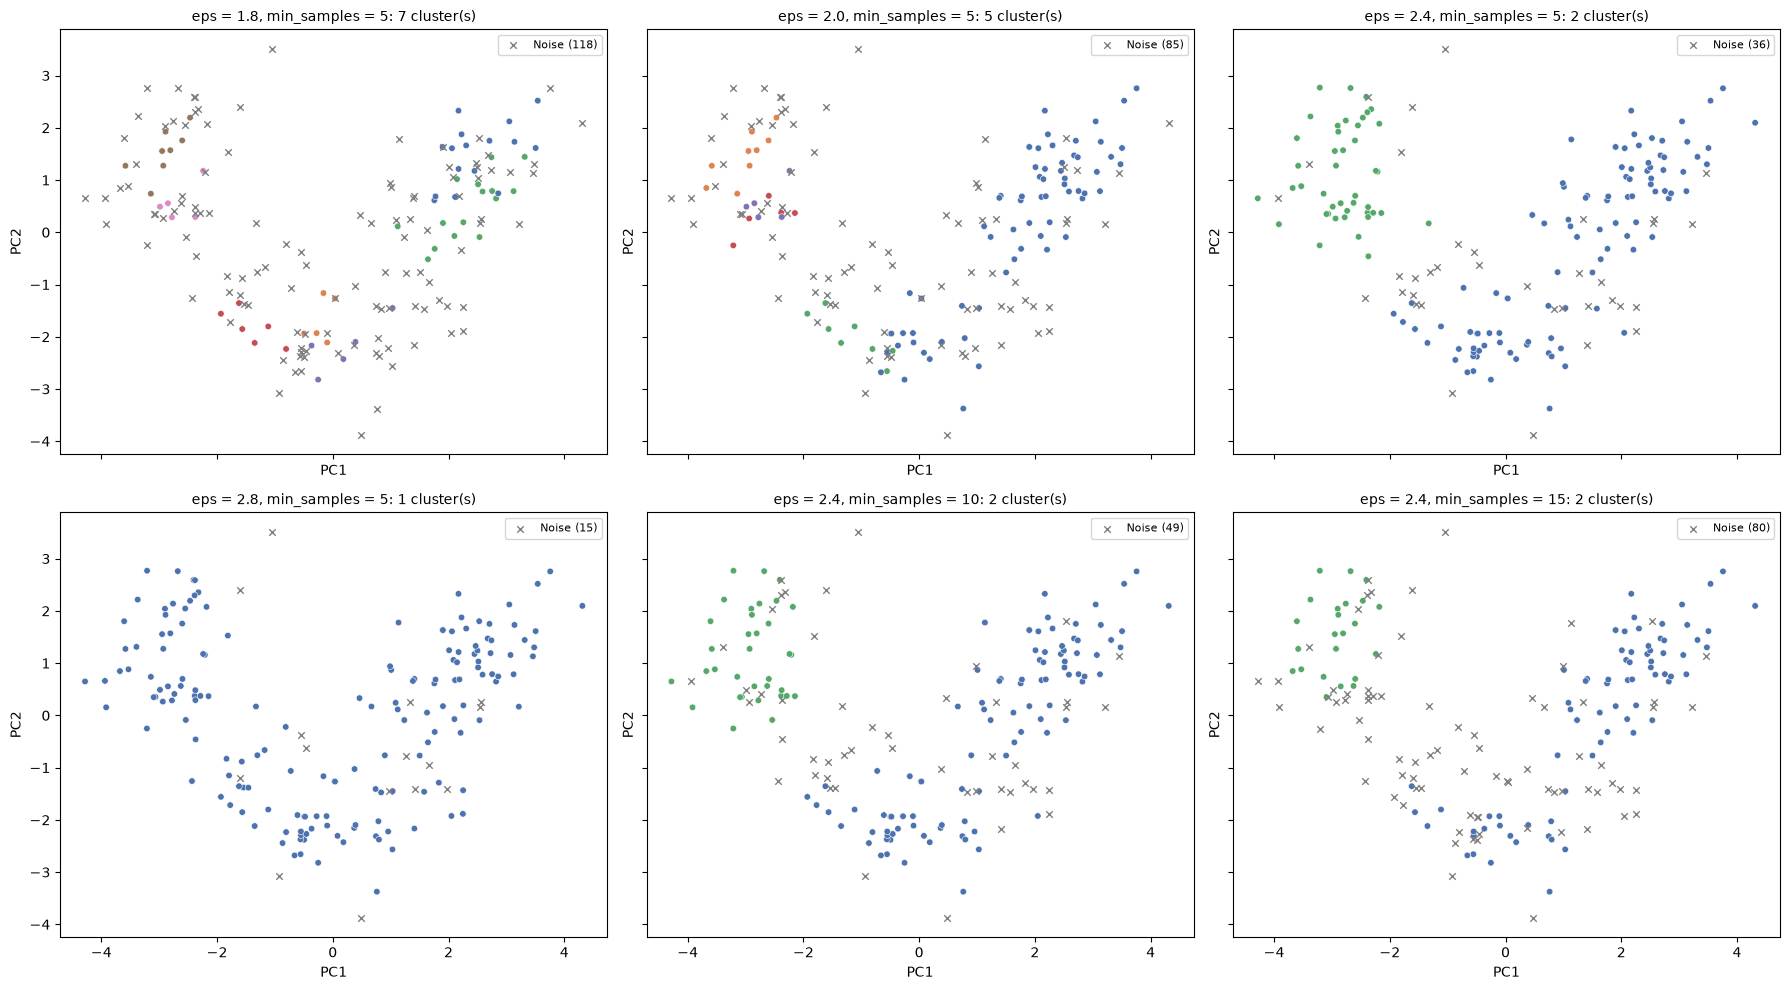

In [18]:
settings = [(1.8, 5), (2.0, 5), (2.4, 5), (2.8, 5), (2.4, 10), (2.4, 15)]
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
for ax, (eps, ms) in zip(axes.ravel(), settings):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X)
    m = metrics(labels)
    scatter(ax, labels, f"eps = {eps}, min_samples = {ms}: {m['clusters']} cluster(s)")
plt.tight_layout()
plt.show()

### Selected DBSCAN model

The elbow of the k-distance plot (eps ≈ 2.71) falls in the region where DBSCAN merges almost every wine into one cluster, so the heuristic does not work on this dataset. Instead, eps = 2.4 with min_samples = 5 was selected by looking only at the unsupervised results: it is the largest eps, and so produces the least noise, before the clusters merge into one. The two-cluster structure is also stable across neighboring settings (eps 2.2 to 2.4 at min_samples = 5, and 2.2 to 2.6 at min_samples = 10). The true labels were not used to choose these parameters.

In [19]:
db = DBSCAN(eps=2.4, min_samples=5).fit(X)
db_labels = db.labels_
db_metrics = metrics(db_labels)
print('core points:', len(db.core_sample_indices_), ' border points:',
      int((db_labels != -1).sum()) - len(db.core_sample_indices_), ' noise points:', db_metrics['noise points'])
print(f"silhouette (non-noise points):     {db_metrics['silhouette']:.4f}")
print(f"silhouette (noise as its own group): {silhouette_score(X, db_labels):.4f}")
print(f"homogeneity:  {db_metrics['homogeneity']:.4f}")
print(f"completeness: {db_metrics['completeness']:.4f}")
print(f"ARI:          {db_metrics['ARI']:.4f}")

core_mask = db_labels != -1
print(f"homogeneity / completeness on non-noise points only: "
      f"{homogeneity_score(y[core_mask], db_labels[core_mask]):.4f} / {completeness_score(y[core_mask], db_labels[core_mask]):.4f}")

core points: 115  border points: 27  noise points: 36
silhouette (non-noise points):     0.3266
silhouette (noise as its own group): 0.1959
homogeneity:  0.5044
completeness: 0.5519
ARI:          0.4205
homogeneity / completeness on non-noise points only: 0.5327 / 0.9455


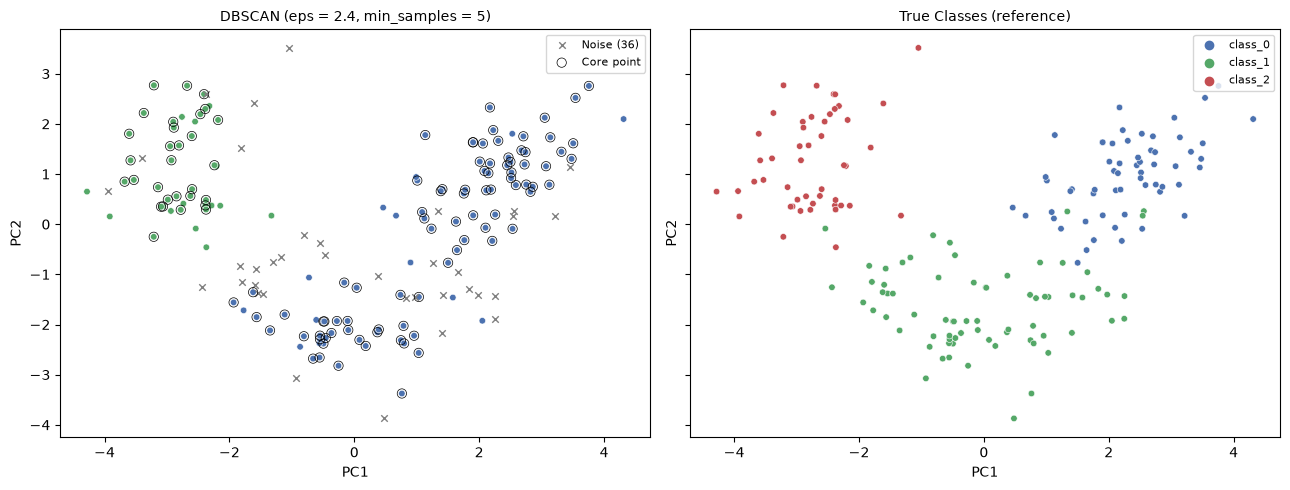

dbscan cluster,0,1,noise
true class,,,
class_0,57,0,2
class_1,42,1,28
class_2,0,42,6


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
scatter(axes[0], db_labels, 'DBSCAN (eps = 2.4, min_samples = 5)')
core = np.zeros(len(X), bool); core[db.core_sample_indices_] = True
axes[0].scatter(X_2d[core, 0], X_2d[core, 1], facecolor='none', edgecolor='black', s=45, linewidth=0.5, label='Core point')
axes[0].legend(loc='upper right', fontsize=8)
scatter(axes[1], y, 'True Classes (reference)')
for i, n in enumerate(class_names):
    axes[1].scatter([], [], c=palette[i], label=n)
axes[1].legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

pd.crosstab(pd.Series([class_names[i] for i in y], name='true class'),
            pd.Series(np.where(db_labels == -1, 'noise', db_labels.astype(str)), name='dbscan cluster'))

**Observation:** With eps = 2.4 and min_samples = 5, DBSCAN finds 115 core points, 27 border points, and 36 noise points, arranged in two clusters:

* **Cluster 0 (99 wines):** 57 class_0 wines and 42 class_1 wines. DBSCAN connects these two cultivars because the dense part of class_1 touches class_0 in feature space.
* **Cluster 1 (43 wines):** 42 class_2 wines and 1 class_1 wine, a near-perfect match to class_2.
* **Noise (36 wines):** 28 of them (78%) are class_1. These are the spread-out class_1 wines that are not dense enough to belong to any cluster.

The resulting scores are homogeneity 0.5044, completeness 0.5519, and ARI 0.4205. On the non-noise points alone, completeness is 0.9455 but homogeneity is only 0.5327. Each cultivar's dense core sits almost entirely inside one cluster, but one cluster contains two cultivars. The silhouette is 0.3266 on non-noise points and 0.1959 when noise is counted as its own group. The higher value is the standard way to report DBSCAN, but it flatters the model: it scores only the 142 wines DBSCAN chose to keep and drops the 36 hardest cases.

### Supplementary: DBSCAN in two dimensions

DBSCAN's difficulty in 13 dimensions is expected: as dimensions increase, distances between points become more similar to one another, and density becomes harder to tell apart. To test this, DBSCAN is applied to the 2-dimensional PCA projection, with eps chosen on that projection's scale.

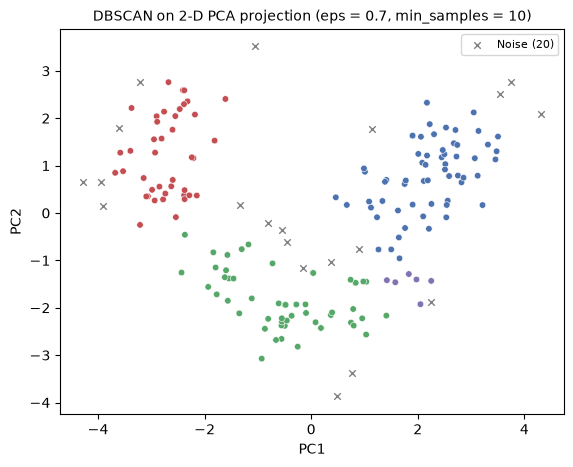

,eps,min_samples,clusters,noise points,silhouette,homogeneity,completeness,ARI
0,0.5,5,5,31,0.523,0.625,0.416,0.379
1,0.5,10,4,101,0.809,0.432,0.374,0.173
2,0.6,5,2,16,0.499,0.465,0.605,0.431
3,0.6,10,5,53,0.630,0.641,0.423,0.372
4,0.7,5,2,6,0.480,0.449,0.688,0.437
5,0.7,10,4,20,0.450,0.753,0.575,0.663
6,0.8,5,2,5,0.478,0.449,0.706,0.438
7,0.8,10,2,7,0.486,0.464,0.695,0.449


In [21]:
pca_rows = []
for eps in [0.5, 0.6, 0.7, 0.8]:
    for ms in [5, 10]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_2d)
        pca_rows.append({'eps': eps, 'min_samples': ms, **metrics(labels, X_data=X_2d)})
pca_df = pd.DataFrame(pca_rows).round(3)

best_2d = DBSCAN(eps=0.7, min_samples=10).fit_predict(X_2d)
fig, ax = plt.subplots(figsize=(6.5, 5))
scatter(ax, best_2d, 'DBSCAN on 2-D PCA projection (eps = 0.7, min_samples = 10)')
plt.show()
pca_df

**Observation:** In two dimensions, DBSCAN performs much better. With eps = 0.7 and min_samples = 10, it finds three large clusters matching the three cultivars, plus one small cluster of class_1 wines near the class_0 boundary, with only 20 noise points. Homogeneity rises to 0.7527 and ARI to 0.6631. This supports the explanation that DBSCAN's weak result in 13 dimensions comes from the dimensionality. In high-dimensional space, distances between points become more uniform, so a single density threshold struggles to separate the cultivars. Projecting to two dimensions concentrates the main structure and makes the density differences visible. The trade-off is that the 2-D projection keeps only 55.4% of the variance.

## Step 4: Analysis and Insights

In [22]:
summary = pd.DataFrame([
    {'model': 'Hierarchical (Ward, n_clusters = 3)', **metrics(hier_labels[3])},
    {'model': 'Hierarchical (single, n_clusters = 3)', **metrics(link_labels['single'])},
    {'model': 'DBSCAN (eps = 2.4, min_samples = 5)', **db_metrics},
    {'model': 'DBSCAN on 2-D PCA (eps = 0.7, min_samples = 10)', **metrics(best_2d, X_data=X_2d)},
]).set_index('model')
summary.round(4)

,clusters,noise points,silhouette,homogeneity,completeness,ARI
model,,,,,,
"Hierarchical (Ward, n_clusters = 3)",3,0,0.2774,0.7904,0.7825,0.7899
"Hierarchical (single, n_clusters = 3)",3,0,0.1827,0.0194,0.1752,-0.0068
"DBSCAN (eps = 2.4, min_samples = 5)",2,36,0.3266,0.5044,0.5519,0.4205
"DBSCAN on 2-D PCA (eps = 0.7, min_samples = 10)",4,20,0.4498,0.7527,0.5746,0.6631


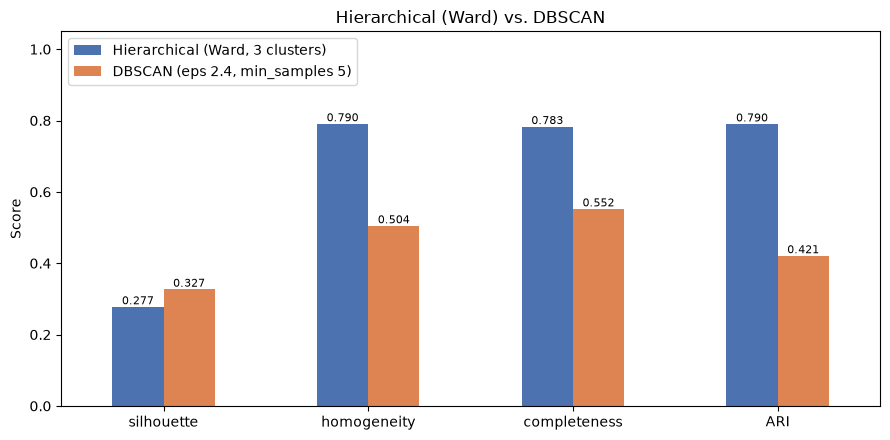

In [23]:
plot_df = summary.loc[['Hierarchical (Ward, n_clusters = 3)', 'DBSCAN (eps = 2.4, min_samples = 5)'],
                      ['silhouette', 'homogeneity', 'completeness', 'ARI']]
ax = plot_df.T.plot(kind='bar', figsize=(9, 4.5), color=['#4C72B0', '#DD8452'], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt='%.3f', fontsize=8)
ax.set_ylim(0, 1.05)
ax.set_ylabel('Score')
ax.set_title('Hierarchical (Ward) vs. DBSCAN')
ax.legend(['Hierarchical (Ward, 3 clusters)', 'DBSCAN (eps 2.4, min_samples 5)'], loc='upper left')
plt.tight_layout()
plt.show()

### Comparison of results

| | Hierarchical (Ward, 3 clusters) | DBSCAN (eps 2.4, min_samples 5) |
|---|---|---|
| Clusters found | 3 | 2 |
| Noise points | 0 | 36 (20%) |
| Silhouette | 0.277 (all points) | 0.327 (non-noise) / 0.196 (all points) |
| Homogeneity | **0.790** | 0.504 |
| Completeness | **0.783** | 0.552 |
| ARI | **0.790** | 0.421 |

**Hierarchical clustering with Ward linkage produced the better clustering for this dataset.** It recovered all three cultivars, assigning 165 of 178 wines to a cluster matching their class, and scored far higher on homogeneity, completeness, and ARI. DBSCAN separated class_2 almost perfectly, but it merged class_0 with the dense part of class_1 and labeled most of the remaining class_1 wines as noise. Its higher silhouette on non-noise points does not mean better clusters. It comes from forming only two groups and leaving out the 36 most ambiguous wines. Counting those wines, its silhouette (0.196) falls below Ward's (0.277).

The two methods agree on the structure of the data: class_2 is the most distinct cultivar, and class_1 is the spread-out group in the middle that touches the other two. Ward expresses this through its merge order (class_2 joins last in the dendrogram), and DBSCAN through its noise (78% of noise points are class_1).

### How parameter choices influenced the outcomes

* **Hierarchical: number of clusters.** This was the most direct control. Silhouette and ARI both peaked at n_clusters = 3, and the dendrogram's large gap between merge heights (12.6 to 27.7) confirmed 3 without using the labels. Fewer clusters merged cultivars, and more clusters split them.
* **Hierarchical: linkage method.** This mattered even more. Ward and complete linkage found meaningful groups, while average and single linkage collapsed into one large cluster plus a few outliers (ARI near 0). Changing linkage changed the result more than any choice of n_clusters.
* **DBSCAN: eps.** eps controlled whether DBSCAN found anything useful. The workable range was narrow (2.2 to 2.4 at min_samples = 5), and a change of 0.2 in either direction turned two clusters into mostly noise or into a single cluster. The standard k-distance heuristic suggested eps = 2.71, which already falls in the single-cluster region, so the parameter could not be chosen by the usual rule.
* **DBSCAN: min_samples.** min_samples traded noise for robustness. Higher values made the clusters denser and more conservative, at the cost of labeling more wines as noise (36 to 80 at eps = 2.4), and shifted the useful eps range upward.

### Strengths and weaknesses of each algorithm

**Hierarchical clustering (Ward)**
* *Strengths:* It produced the most accurate clusters here and is deterministic (the same input always gives the same result). The dendrogram shows the full structure at every level, so the number of clusters can be chosen from the data's own merge distances, and it reveals relationships between groups, such as which cultivar is most distinct.
* *Weaknesses:* It requires choosing a linkage method, and a poor choice (single or average here) fails badly. It assigns every point to a cluster, so ambiguous or outlying wines are forced into a group instead of being flagged. It also compares all pairs of points, which becomes slow and memory-heavy on large datasets.

**DBSCAN**
* *Strengths:* It does not need the number of clusters in advance, it can find clusters of irregular shape, and it identifies outliers explicitly. Here, its noise label correctly singled out the ambiguous class_1 wines that the other methods simply forced into a cluster.
* *Weaknesses:* It is highly sensitive to eps and min_samples, with a narrow working range that the standard k-distance heuristic missed. It uses a single density threshold, so it struggles when clusters have different densities (compact class_0 and class_2 versus spread-out class_1) or when clusters touch, as class_0 and class_1 do. It also degrades in high dimensions, which the 2-D experiment confirmed (ARI 0.421 in 13 dimensions versus 0.663 in 2).

**Overall:** For compact, roughly round clusters with no real noise, like the Wine cultivars, hierarchical clustering with Ward linkage is the better tool. DBSCAN is better suited to low-dimensional data with irregularly shaped clusters, or to tasks where finding outliers matters as much as finding groups, such as spatial data or anomaly detection.